# Stock Market Impact Prediction from Financial News
Pipeline: real Alpaca News (2-year history) + real Alpaca 1-minute OHLCV bars -> cleaning/NER -> **real** return-based labeling (Spike / Neutral / Crash) -> feature engineering & scaling -> chronological split -> BERT fine-tuning -> evaluation -> inference.

> **Setup required before running:** put `config.py` and `logger_setup.py` (provided as separate files) in the **same folder** as this notebook, then open `config.py` and fill in your real `ALPACA_API_KEY` / `ALPACA_SECRET_KEY`.

## Load configuration & logger
Both live in standalone files next to this notebook (not generated inline), so they're easy to re-use, version-control, and edit without touching the notebook.

In [1]:
# cell: project directories, config, and logger
import os

os.makedirs("logs", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

import config as cfg                    # config.py -> all settings + API keys
from logger_setup import setup_logger   # logger_setup.py -> persistent file+console logger

logger = setup_logger()
logger.info("Project directories ready. Logging module initialized successfully.")

if cfg.ALPACA_API_KEY == "YOUR_ALPACA_API_KEY":
    logger.warning("ALPACA_API_KEY is still a placeholder - edit config.py before running Step 1.")

[2026-09-26 03:23:04] INFO: Project directories ready. Logging module initialized successfully.
INFO:StockImpactLogger:Project directories ready. Logging module initialized successfully.


In [2]:
# cell: package installation
# yfinance removed: it only supports ~7-30 days of 1-minute history, which is
# useless for a 2-year study. alpaca-py replaces it for BOTH news and bars.
!pip install -q pandas numpy matplotlib seaborn scikit-learn torch transformers alpaca-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.9/128.9 kB 9.5 MB/s eta 0:00:00


## Imports & global configuration load

In [3]:
# cell: imports
import re
import math
import random
import pickle
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score

from alpaca.data.historical.news import NewsClient
from alpaca.data.historical.stock import StockHistoricalDataClient
from alpaca.data.requests import NewsRequest, StockBarsRequest
from alpaca.data.timeframe import TimeFrame
from alpaca.data.enums import DataFeed

import config as cfg

torch.manual_seed(cfg.SEED)
np.random.seed(cfg.SEED)
random.seed(cfg.SEED)

logger.info(f"Using compute device: {cfg.DEVICE}")

[2026-09-26 03:23:31] INFO: Using compute device: cuda
INFO:StockImpactLogger:Using compute device: cuda


## Step 1 - Real News Ingestion (Alpaca News API, ~2 years)
This step is cached to disk: if `data/raw_alpaca_news.csv` already exists, it is loaded straight from disk instead of re-hitting the API. Set `FORCE_REFRESH_NEWS = True` below to force a fresh pull (e.g. if you changed `NEWS_LOOKBACK_DAYS`).

In [4]:
# cell: fetch real news from Alpaca (cached)
# NOTE: alpaca-py's NewsClient.get_news() already paginates internally
# (it keeps calling the API in 50-article pages until Alpaca stops returning
# a next_page_token) - we must NOT set `limit`, because the SDK treats
# `limit` as a hard cap on the TOTAL number of articles across ALL pages,
# not a per-page size. Setting limit=50 is why earlier runs only got 50
# articles per ticker no matter how long the date range was.
FORCE_REFRESH_NEWS = False
RAW_NEWS_PATH = "data/raw_alpaca_news.csv"

news_client = NewsClient(cfg.ALPACA_API_KEY, cfg.ALPACA_SECRET_KEY)

def fetch_company_news(ticker, lookback_days=cfg.NEWS_LOOKBACK_DAYS):
    """Pulls every news article for one ticker over the lookback window.
    A single get_news() call already walks every page internally."""
    start = datetime.now(timezone.utc) - timedelta(days=lookback_days)
    end = datetime.now(timezone.utc)

    request_params = NewsRequest(
        symbols=ticker,
        start=start,
        end=end,
        include_content=False,
        exclude_contentless=True,
        # limit intentionally omitted -> SDK fetches ALL available pages
    )
    response = news_client.get_news(request_params)

    try:
        batch_df = response.df.reset_index(drop=True)
    except Exception:
        articles = getattr(response, "data", {}).get("news", [])
        batch_df = pd.DataFrame([a.dict() if hasattr(a, "dict") else a.__dict__ for a in articles])

    if batch_df.empty:
        return batch_df

    batch_df["Query_Ticker"] = ticker
    return batch_df

if os.path.exists(RAW_NEWS_PATH) and not FORCE_REFRESH_NEWS:
    logger.info(f"Found cached news at '{RAW_NEWS_PATH}' - loading from disk (set FORCE_REFRESH_NEWS=True to re-fetch).")
    raw_news_df = pd.read_csv(RAW_NEWS_PATH, parse_dates=["Timestamp"])
else:
    news_frames = []
    for company_name, ticker in cfg.COMPANIES.items():
        logger.info(f"Fetching {cfg.NEWS_LOOKBACK_DAYS} days of news for {company_name} ({ticker})...")
        df_t = fetch_company_news(ticker)
        logger.info(f"  -> {len(df_t)} articles retrieved for {ticker}")
        news_frames.append(df_t)

    raw_news_df = pd.concat(news_frames, ignore_index=True) if news_frames else pd.DataFrame()

# Normalize column names across SDK versions (defensive: don't assume any
# specific column exists, since alpaca-py's News df layout can vary slightly
# between versions)
rename_map = {}
if "created_at" in raw_news_df.columns:
    rename_map["created_at"] = "Timestamp"
if "headline" in raw_news_df.columns:
    rename_map["headline"] = "Headline"
if "id" in raw_news_df.columns:
    rename_map["id"] = "News ID"
raw_news_df = raw_news_df.rename(columns=rename_map)

# Guarantee the columns the rest of the notebook depends on always exist
if "News ID" not in raw_news_df.columns:
    raw_news_df["News ID"] = [f"NEWS_{i}" for i in range(len(raw_news_df))]
if "Headline" not in raw_news_df.columns:
    raise KeyError(
        f"Could not find a headline column in the Alpaca News response. "
        f"Columns returned: {list(raw_news_df.columns)}. Update rename_map above to match."
    )
if "Timestamp" not in raw_news_df.columns:
    raise KeyError(
        f"Could not find a timestamp column in the Alpaca News response. "
        f"Columns returned: {list(raw_news_df.columns)}. Update rename_map above to match."
    )

raw_news_df["Timestamp"] = pd.to_datetime(raw_news_df["Timestamp"], utc=True).dt.tz_convert("America/New_York")
raw_news_df = raw_news_df.sort_values("Timestamp").reset_index(drop=True)

raw_news_df.to_csv("data/raw_alpaca_news.csv", index=False)
logger.info(f"Saved {len(raw_news_df)} raw news records to data/raw_alpaca_news.csv")
raw_news_df.head(5)

[2026-09-26 03:23:31] INFO: Fetching 730 days of news for Apple (AAPL)...
INFO:StockImpactLogger:Fetching 730 days of news for Apple (AAPL)...
[2026-09-26 03:23:58] INFO:   -> 5154 articles retrieved for AAPL
INFO:StockImpactLogger:  -> 5154 articles retrieved for AAPL
[2026-09-26 03:23:58] INFO: Fetching 730 days of news for Microsoft (MSFT)...
INFO:StockImpactLogger:Fetching 730 days of news for Microsoft (MSFT)...
[2026-09-26 03:24:24] INFO:   -> 4950 articles retrieved for MSFT
INFO:StockImpactLogger:  -> 4950 articles retrieved for MSFT
[2026-09-26 03:24:24] INFO: Fetching 730 days of news for NVIDIA (NVDA)...
INFO:StockImpactLogger:Fetching 730 days of news for NVIDIA (NVDA)...
[2026-09-26 03:25:07] INFO:   -> 8435 articles retrieved for NVDA
INFO:StockImpactLogger:  -> 8435 articles retrieved for NVDA
[2026-09-26 03:25:07] INFO: Fetching 730 days of news for Tesla (TSLA)...
INFO:StockImpactLogger:Fetching 730 days of news for Tesla (TSLA)...
[2026-09-26 03:25:43] INFO:   -> 7220

,Headline,source,url,summary,Timestamp,updated_at,symbols,author,content,images,Query_Ticker,News ID
0,Analyst On WeWork: High Growth Equals High Cas...,benzinga,https://www.benzinga.com/analyst-ratings/analy...,WeWork is postponing its initial public offeri...,2019-09-17 13:26:14-04:00,2024-11-18 20:08:06+00:00,[MSFT],Jayson Derrick,,"[{'size': 'NewsImageSize.LARGE', 'url': 'https...",MSFT,NEWS_9764
1,Microsoft Analysts On Redmond's Q3 Beat: 'A Co...,benzinga,https://www.benzinga.com/analyst-ratings/analy...,Microsoft Corporation (NASDAQ: MSFT) reported ...,2020-04-30 11:47:08-04:00,2024-11-18 19:58:04+00:00,[MSFT],Shanthi Rexaline,,"[{'size': 'NewsImageSize.LARGE', 'url': 'https...",MSFT,NEWS_9765
2,What To Know About The Conflicting AMC Enterta...,benzinga,https://www.benzinga.com/m-a/20/05/16014823/wh...,Editor&#39;s note: This story has been updated...,2020-05-13 12:32:36-04:00,2024-11-18 19:56:41+00:00,"[AMC, AMCX, AMZN]",Tanzeel Akhtar,,"[{'size': 'NewsImageSize.LARGE', 'url': 'https...",AMZN,NEWS_30628
3,Ukraine Gets 150 Starlinks From Poland While E...,benzinga,https://www.benzinga.com/tech/24/10/42708683/u...,,2022-10-14 06:25:58-04:00,2024-12-30 15:17:14+00:00,[TSLA],Navdeep Yadav,,"[{'size': 'NewsImageSize.LARGE', 'url': 'https...",TSLA,NEWS_24746
4,Tesla Vs. Toyota: Electric Dreams Clash With H...,benzinga,https://www.benzinga.com/markets/equities/23/1...,The battle between electric vehicles and hybri...,2023-11-25 11:27:43-05:00,2024-11-05 19:14:49+00:00,"[TM, TSLA]",Nabaparna Bhattacharya,,"[{'size': 'NewsImageSize.LARGE', 'url': 'https...",TSLA,NEWS_25312


### EDA - raw news

/tmp/ipykernel_765/1095555207.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  raw_news_df["Timestamp"].dt.to_period("M").value_counts().sort_index().plot(ax=axes[1])


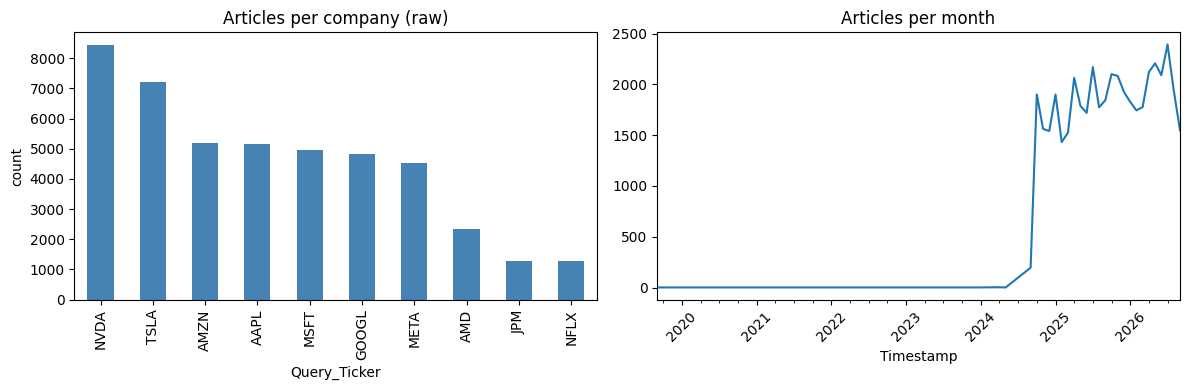

Date range: 2019-09-17 13:26:14-04:00 -> 2026-09-25 16:02:05-04:00
Missing headlines: 0


In [5]:
# cell: raw news EDA
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

raw_news_df["Query_Ticker"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Articles per company (raw)")
axes[0].set_ylabel("count")

raw_news_df["Timestamp"].dt.to_period("M").value_counts().sort_index().plot(ax=axes[1])
axes[1].set_title("Articles per month")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(f"Date range: {raw_news_df['Timestamp'].min()} -> {raw_news_df['Timestamp'].max()}")
print(f"Missing headlines: {raw_news_df['Headline'].isna().sum()}")

## Step 2 - Text Cleaning & Entity Resolution

In [6]:
# cell: cleaning + ticker resolution (single, de-duplicated implementation)
def clean_headline(text):
    """Removes URLs, promo punctuation, and normalizes whitespace."""
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s\.\,\$\%]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def resolve_ticker(headline, query_ticker, symbols_field):
    """Prefers the ticker Alpaca already tagged the article with (Query_Ticker /
    symbols_field); falls back to a dictionary lookup in the headline text."""
    if isinstance(query_ticker, str) and query_ticker in cfg.COMPANIES.values():
        return query_ticker

    if isinstance(symbols_field, (list, tuple)):
        for item in symbols_field:
            if item in cfg.COMPANIES.values():
                return item
    elif isinstance(symbols_field, str):
        for ticker in cfg.COMPANIES.values():
            if ticker in symbols_field:
                return ticker

    headline_lower = headline.lower()
    for synonym, ticker in cfg.ENTITY_RESOLVER.items():
        if re.search(r"\b" + re.escape(synonym) + r"\b", headline_lower):
            return ticker

    return None

news_df = pd.read_csv("data/raw_alpaca_news.csv", parse_dates=["Timestamp"])

if "News ID" not in news_df.columns:
    news_df["News ID"] = [f"NEWS_{i}" for i in range(len(news_df))]

news_df["Cleaned_Headline"] = news_df["Headline"].apply(clean_headline)
symbols_col = news_df["symbols"] if "symbols" in news_df.columns else pd.Series([None] * len(news_df))
news_df["Matched_Ticker"] = [
    resolve_ticker(h, qt, sym)
    for h, qt, sym in zip(news_df["Cleaned_Headline"], news_df.get("Query_Ticker"), symbols_col)
]

before = len(news_df)
news_df = news_df.dropna(subset=["Matched_Ticker", "Cleaned_Headline"]).copy()
news_df = news_df[news_df["Cleaned_Headline"].str.len() > 0].reset_index(drop=True)

news_df.to_csv("data/cleaned_alpaca_news.csv", index=False)
logger.info(f"Cleaning complete: {len(news_df)} / {before} usable records kept.")

preview_cols = [c for c in ["News ID", "Cleaned_Headline", "Matched_Ticker", "Timestamp"] if c in news_df.columns]
news_df[preview_cols].head(5)

[2026-09-26 03:27:30] INFO: Cleaning complete: 45185 / 45185 usable records kept.
INFO:StockImpactLogger:Cleaning complete: 45185 / 45185 usable records kept.


,News ID,Cleaned_Headline,Matched_Ticker,Timestamp
0,NEWS_9764,Analyst On WeWork High Growth Equals High Cash...,MSFT,2019-09-17 13:26:14-04:00
1,NEWS_9765,Microsoft Analysts On Redmonds Q3 Beat A Core ...,MSFT,2020-04-30 11:47:08-04:00
2,NEWS_30628,What To Know About The Conflicting AMC Enterta...,AMZN,2020-05-13 12:32:36-04:00
3,NEWS_24746,Ukraine Gets 150 Starlinks From Poland While E...,TSLA,2022-10-14 06:25:58-04:00
4,NEWS_25312,Tesla Vs. Toyota Electric Dreams Clash With Hy...,TSLA,2023-11-25 11:27:43-05:00


### EDA - cleaned data

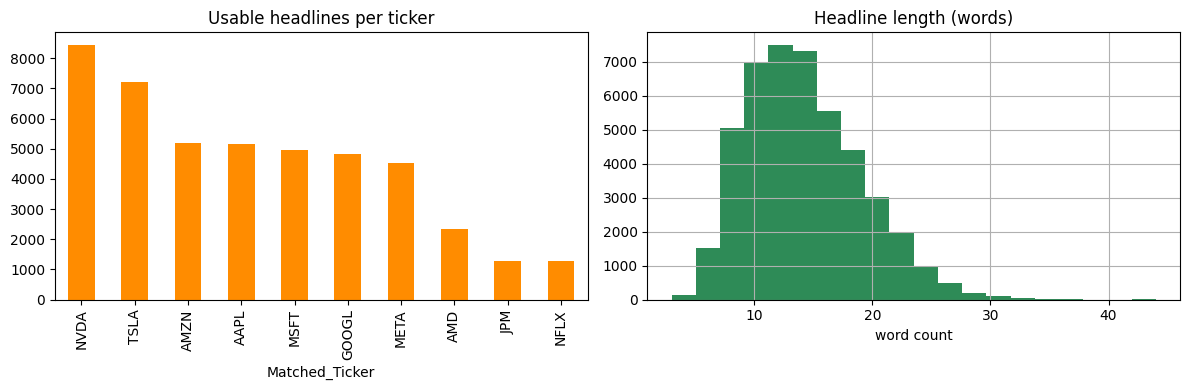

In [7]:
# cell: cleaned-data EDA
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

news_df["Matched_Ticker"].value_counts().plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set_title("Usable headlines per ticker")

news_df["Cleaned_Headline"].str.split().apply(len).hist(bins=20, ax=axes[1], color="seagreen")
axes[1].set_title("Headline length (words)")
axes[1].set_xlabel("word count")

plt.tight_layout()
plt.show()

## Step 3 - Historical 1-Minute OHLCV Ingestion (Alpaca, IEX free feed)
Also cached per-ticker as `data/bars_<TICKER>.parquet`. Set `FORCE_REFRESH_BARS = True` in the cell below to force a fresh download.

In [8]:
# cell: fetch real 1-minute bars for every ticker
# Same fix as Step 1: get_stock_bars() already paginates internally, and
# `limit` is a TOTAL cap across all pages, not a per-page size. Leaving it
# unset lets the SDK pull the full lookback window instead of stopping
# after ~10,000 bars (~25 trading days).
stock_client = StockHistoricalDataClient(cfg.ALPACA_API_KEY, cfg.ALPACA_SECRET_KEY)

def fetch_minute_bars(ticker, lookback_days=cfg.NEWS_LOOKBACK_DAYS):
    """Downloads every 1-minute OHLCV bar for a ticker over the lookback
    window. Uses feed=IEX, which is what free Alpaca accounts are entitled to."""
    start = datetime.now(timezone.utc) - timedelta(days=lookback_days)
    end = datetime.now(timezone.utc)

    request_params = StockBarsRequest(
        symbol_or_symbols=ticker,
        timeframe=TimeFrame.Minute,
        start=start,
        end=end,
        feed=DataFeed.IEX,
        # limit intentionally omitted -> SDK fetches every page available
    )
    bar_set = stock_client.get_stock_bars(request_params)
    out = bar_set.df

    if out is None or out.empty:
        return pd.DataFrame()

    if isinstance(out.index, pd.MultiIndex):
        out = out.droplevel(0)  # drop the symbol level, keep timestamp index
    out = out.sort_index()
    out.index = out.index.tz_convert("America/New_York")
    return out

stock_dict = {}
FORCE_REFRESH_BARS = False
for ticker in cfg.COMPANIES.values():
    cache_path = f"data/bars_{ticker}.parquet"
    if os.path.exists(cache_path) and not FORCE_REFRESH_BARS:
        logger.info(f"Found cached bars at '{cache_path}' - loading from disk (set FORCE_REFRESH_BARS=True to re-fetch).")
        bars_df = pd.read_parquet(cache_path)
    else:
        logger.info(f"Downloading {cfg.NEWS_LOOKBACK_DAYS} days of 1-min bars for {ticker}...")
        bars_df = fetch_minute_bars(ticker)
        bars_df.to_parquet(cache_path)
    stock_dict[ticker] = bars_df
    logger.info(f"  -> {len(bars_df)} 1-minute candles available for {ticker}")

[2026-09-26 03:27:31] INFO: Downloading 730 days of 1-min bars for AAPL...
INFO:StockImpactLogger:Downloading 730 days of 1-min bars for AAPL...
[2026-09-26 03:27:44] INFO:   -> 195005 1-minute candles available for AAPL
INFO:StockImpactLogger:  -> 195005 1-minute candles available for AAPL
[2026-09-26 03:27:44] INFO: Downloading 730 days of 1-min bars for MSFT...
INFO:StockImpactLogger:Downloading 730 days of 1-min bars for MSFT...
[2026-09-26 03:27:57] INFO:   -> 187581 1-minute candles available for MSFT
INFO:StockImpactLogger:  -> 187581 1-minute candles available for MSFT
[2026-09-26 03:27:57] INFO: Downloading 730 days of 1-min bars for NVDA...
INFO:StockImpactLogger:Downloading 730 days of 1-min bars for NVDA...
[2026-09-26 03:28:11] INFO:   -> 200337 1-minute candles available for NVDA
INFO:StockImpactLogger:  -> 200337 1-minute candles available for NVDA
[2026-09-26 03:28:11] INFO: Downloading 730 days of 1-min bars for TSLA...
INFO:StockImpactLogger:Downloading 730 days of 1-

## Step 4 - News/Price Alignment & Real Label Generation
This is the core fix: the label comes from the **actual close price** `RETURN_WINDOW_MIN` real 1-minute candles after the news timestamp - not from `np.random`.

In [9]:
# cell: real alignment + labeling
def align_news_and_calculate_returns(news_df, stock_dict, forward_window=cfg.RETURN_WINDOW_MIN):
    records = []

    for _, row in news_df.iterrows():
        ticker = row["Matched_Ticker"]
        news_time = row["Timestamp"]

        stk_df = stock_dict.get(ticker)
        if stk_df is None or stk_df.empty:
            continue

        future_candles = stk_df[stk_df.index >= news_time]
        if len(future_candles) <= forward_window:
            continue  # not enough future candles to compute the forward return

        p_initial = future_candles.iloc[0]["close"]
        p_future = future_candles.iloc[forward_window]["close"]
        ret = ((p_future - p_initial) / p_initial) * 100.0

        if ret >= cfg.UPPER_THRESHOLD:
            label = 1  # SPIKE
        elif ret <= cfg.LOWER_THRESHOLD:
            label = 2  # CRASH
        else:
            label = 0  # NEUTRAL

        records.append({
            "News_ID": row.get("News ID"),
            "Headline": row["Cleaned_Headline"],
            "Ticker": ticker,
            "News_Time": news_time,
            "Price_t0": p_initial,
            "Price_t_forward": p_future,
            "Return_Pct": ret,
            "Label": label,
        })

    return pd.DataFrame(records)

LABELED_PATH = "data/labeled_alpaca_dataset.csv"
FORCE_REFRESH_LABELS = False

if os.path.exists(LABELED_PATH) and not FORCE_REFRESH_LABELS:
    logger.info(f"Found cached labeled dataset at '{LABELED_PATH}' - loading from disk "
                f"(set FORCE_REFRESH_LABELS=True to recompute).")
    labeled_df = pd.read_csv(LABELED_PATH, parse_dates=["News_Time"])
else:
    labeled_df = align_news_and_calculate_returns(news_df, stock_dict)

    if labeled_df.empty:
        raise ValueError(
            "No news could be aligned with price data. This usually means stock_dict "
            "is empty/short (check the Step 3 bars fetch above) or every ticker's bars "
            "don't extend far enough forward past the news timestamps. "
            "Inspect stock_dict['AAPL'].shape etc. before re-running this cell."
        )

    labeled_df = labeled_df.sort_values("News_Time").reset_index(drop=True)
    labeled_df.to_csv(LABELED_PATH, index=False)

logger.info(f"Aligned {len(labeled_df)} news records with real forward price movements.")
print(labeled_df["Label"].value_counts().rename({0: "NEUTRAL", 1: "SPIKE", 2: "CRASH"}))

[2026-09-26 03:31:39] INFO: Aligned 45182 news records with real forward price movements.
INFO:StockImpactLogger:Aligned 45182 news records with real forward price movements.


Label
NEUTRAL    19384
CRASH      13331
SPIKE      12467
Name: count, dtype: int64


### EDA - labels & returns

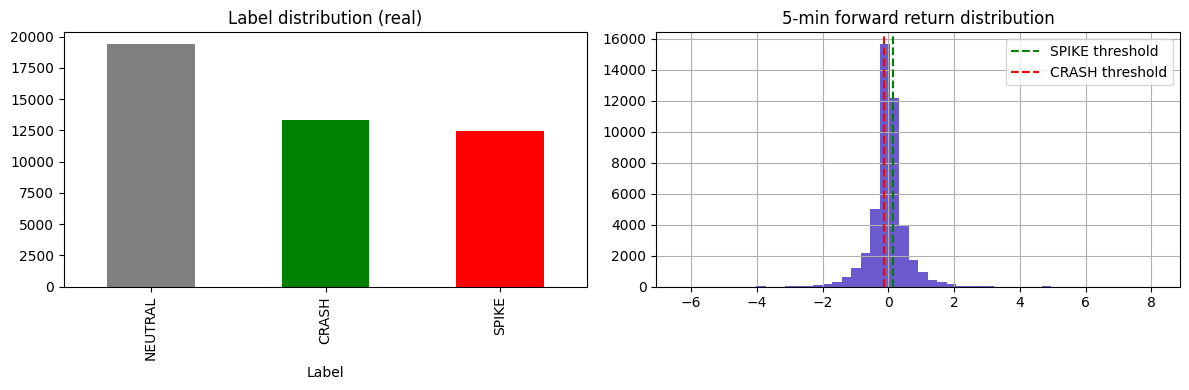

If one class dominates heavily (e.g. NEUTRAL >> 90%), consider a smaller RETURN_WINDOW_MIN or tighter thresholds in config.py, then re-run Step 4.


In [10]:
# cell: label / return EDA
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labeled_df["Label"].map({0: "NEUTRAL", 1: "SPIKE", 2: "CRASH"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["gray", "green", "red"]
)
axes[0].set_title("Label distribution (real)")

labeled_df["Return_Pct"].hist(bins=50, ax=axes[1], color="slateblue")
axes[1].axvline(cfg.UPPER_THRESHOLD, color="green", linestyle="--", label="SPIKE threshold")
axes[1].axvline(cfg.LOWER_THRESHOLD, color="red", linestyle="--", label="CRASH threshold")
axes[1].set_title(f"{cfg.RETURN_WINDOW_MIN}-min forward return distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

print("If one class dominates heavily (e.g. NEUTRAL >> 90%), consider a smaller "
      "RETURN_WINDOW_MIN or tighter thresholds in config.py, then re-run Step 4.")

## Step 5 - Chronological Train/Validation/Test Split
Time-series data must be split in time order (never shuffled/stratified-random), otherwise the model can implicitly \"see the future\" during training.

In [11]:
# cell: chronological split
labeled_df = labeled_df.sort_values("News_Time").reset_index(drop=True)

train_size = int(len(labeled_df) * 0.70)
val_size = int(len(labeled_df) * 0.15)

train_df = labeled_df.iloc[:train_size].reset_index(drop=True)
val_df = labeled_df.iloc[train_size:train_size + val_size].reset_index(drop=True)
test_df = labeled_df.iloc[train_size + val_size:].reset_index(drop=True)

logger.info(f"Chronological split -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Train window: {train_df['News_Time'].min()} -> {train_df['News_Time'].max()}")
print(f"Test window : {test_df['News_Time'].min()} -> {test_df['News_Time'].max()}")

[2026-09-26 03:31:39] INFO: Chronological split -> Train: 31627 | Val: 6777 | Test: 6778
INFO:StockImpactLogger:Chronological split -> Train: 31627 | Val: 6777 | Test: 6778


Train window: 2019-09-17 13:26:14-04:00 -> 2026-03-10 14:18:09-04:00
Test window : 2026-06-17 03:10:58-04:00 -> 2026-09-25 15:43:01-04:00


## Step 6 - Feature Engineering & Scaling
Alongside the headline text (fed to BERT), we engineer a small set of numeric side-features (headline length, time-of-day, day-of-week as cyclical sin/cos) and scale them with `StandardScaler` **fit only on the training split** to avoid leaking test-set statistics. The result (splits + scaled features + scaler) is **cached to `data/features/` and `models/numeric_feature_scaler.pkl`** - after the first successful run you can restart the kernel and this cell will just reload everything instead of recomputing. Set `FORCE_REFRESH_FEATURES = True` to redo it.

In [12]:
# cell: numeric feature engineering + scaling (cached to disk)
FEATURES_DIR = "data/features"
os.makedirs(FEATURES_DIR, exist_ok=True)
FORCE_REFRESH_FEATURES = False

def build_numeric_features(df):
    feats = pd.DataFrame(index=df.index)
    feats["headline_len"] = df["Headline"].str.split().apply(len)

    # Defensive: make sure News_Time is a real datetime dtype regardless of
    # what it looked like coming in (e.g. after a CSV round-trip it can
    # silently become plain strings/objects, which breaks the .dt accessor).
    news_time = pd.to_datetime(df["News_Time"], utc=True, errors="coerce")

    hour = news_time.dt.hour + news_time.dt.minute / 60.0
    feats["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    feats["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    dow = news_time.dt.dayofweek
    feats["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    feats["dow_cos"] = np.cos(2 * np.pi * dow / 7)

    return feats

_cache_files = {
    "train_df": f"{FEATURES_DIR}/train_df.csv",
    "val_df": f"{FEATURES_DIR}/val_df.csv",
    "test_df": f"{FEATURES_DIR}/test_df.csv",
    "train_feats_scaled": f"{FEATURES_DIR}/train_feats_scaled.npy",
    "val_feats_scaled": f"{FEATURES_DIR}/val_feats_scaled.npy",
    "test_feats_scaled": f"{FEATURES_DIR}/test_feats_scaled.npy",
    "scaler": "models/numeric_feature_scaler.pkl",
}
_all_cached = all(os.path.exists(p) for p in _cache_files.values())

if _all_cached and not FORCE_REFRESH_FEATURES:
    logger.info(f"Found cached features in '{FEATURES_DIR}/' - loading from disk "
                f"(set FORCE_REFRESH_FEATURES=True to recompute).")
    train_df = pd.read_csv(_cache_files["train_df"], parse_dates=["News_Time"])
    val_df = pd.read_csv(_cache_files["val_df"], parse_dates=["News_Time"])
    test_df = pd.read_csv(_cache_files["test_df"], parse_dates=["News_Time"])
    train_feats_scaled = np.load(_cache_files["train_feats_scaled"])
    val_feats_scaled = np.load(_cache_files["val_feats_scaled"])
    test_feats_scaled = np.load(_cache_files["test_feats_scaled"])
    with open(_cache_files["scaler"], "rb") as f:
        scaler = pickle.load(f)
else:
    train_feats = build_numeric_features(train_df)
    val_feats = build_numeric_features(val_df)
    test_feats = build_numeric_features(test_df)

    scaler = StandardScaler()
    train_feats_scaled = scaler.fit_transform(train_feats)   # fit on TRAIN ONLY
    val_feats_scaled = scaler.transform(val_feats)
    test_feats_scaled = scaler.transform(test_feats)

    # ---- persist everything so this step never needs to be redone ----
    train_df.to_csv(_cache_files["train_df"], index=False)
    val_df.to_csv(_cache_files["val_df"], index=False)
    test_df.to_csv(_cache_files["test_df"], index=False)
    np.save(_cache_files["train_feats_scaled"], train_feats_scaled)
    np.save(_cache_files["val_feats_scaled"], val_feats_scaled)
    np.save(_cache_files["test_feats_scaled"], test_feats_scaled)
    with open(_cache_files["scaler"], "wb") as f:
        pickle.dump(scaler, f)

    logger.info(f"Saved train/val/test splits + scaled features + scaler to "
                f"'{FEATURES_DIR}/' and 'models/numeric_feature_scaler.pkl'.")

logger.info(f"Numeric feature matrix shapes -> train {train_feats_scaled.shape}, "
            f"val {val_feats_scaled.shape}, test {test_feats_scaled.shape}")

[2026-09-26 03:31:41] INFO: Saved train/val/test splits + scaled features + scaler to 'data/features/' and 'models/numeric_feature_scaler.pkl'.
INFO:StockImpactLogger:Saved train/val/test splits + scaled features + scaler to 'data/features/' and 'models/numeric_feature_scaler.pkl'.
[2026-09-26 03:31:41] INFO: Numeric feature matrix shapes -> train (31627, 5), val (6777, 5), test (6778, 5)
INFO:StockImpactLogger:Numeric feature matrix shapes -> train (31627, 5), val (6777, 5), test (6778, 5)


## Step 7 - PyTorch Dataset & Tokenizer

In [13]:
# cell: dataset class (text + scaled numeric features + label)
tokenizer = AutoTokenizer.from_pretrained(cfg.MODEL_NAME)

class NewsImpactDataset(Dataset):
    def __init__(self, headlines, numeric_feats, labels, tokenizer, max_len=cfg.MAX_LEN):
        self.headlines = list(headlines)
        self.numeric_feats = np.asarray(numeric_feats, dtype=np.float32)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.headlines)

    def __getitem__(self, item):
        headline = str(self.headlines[item])
        encoding = self.tokenizer(
            headline,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )
        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "numeric_feats": torch.tensor(self.numeric_feats[item], dtype=torch.float32),
            "labels": torch.tensor(self.labels[item], dtype=torch.long),
        }

train_loader = DataLoader(
    NewsImpactDataset(train_df["Headline"].values, train_feats_scaled, train_df["Label"].values, tokenizer),
    batch_size=cfg.BATCH_SIZE, shuffle=True,
)
val_loader = DataLoader(
    NewsImpactDataset(val_df["Headline"].values, val_feats_scaled, val_df["Label"].values, tokenizer),
    batch_size=cfg.BATCH_SIZE,
)
test_loader = DataLoader(
    NewsImpactDataset(test_df["Headline"].values, test_feats_scaled, test_df["Label"].values, tokenizer),
    batch_size=cfg.BATCH_SIZE,
)

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## Step 8 - Model Definition (BERT encoder + numeric-feature fusion)

In [14]:
# cell: model
class StockImpactClassifier(nn.Module):
    def __init__(self, model_name, numeric_dim=cfg.NUMERIC_FEATURE_DIM, num_classes=3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size

        self.numeric_proj = nn.Sequential(
            nn.Linear(numeric_dim, 32),
            nn.ReLU(),
        )
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden + 32, num_classes)

    def forward(self, input_ids, attention_mask, numeric_feats):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = outputs.pooler_output if hasattr(outputs, "pooler_output") else outputs.last_hidden_state[:, 0, :]
        num_out = self.numeric_proj(numeric_feats)
        fused = torch.cat([pooled, num_out], dim=1)
        return self.classifier(self.dropout(fused))

model = StockImpactClassifier(cfg.MODEL_NAME).to(cfg.DEVICE)
logger.info("Fusion model (BERT + numeric features) loaded onto compute device.")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ProsusAI/finbert
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[2026-09-26 03:31:52] INFO: Fusion model (BERT + numeric features) loaded onto compute device.
INFO:StockImpactLogger:Fusion model (BERT + numeric features) loaded onto compute device.


## Step 9 - Training Loop (best checkpoint by validation macro-F1)

In [15]:
# cell: training
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LEARNING_RATE)

best_val_f1 = -1.0
best_model_path = "models/best_stock_impact_model.pt"

logger.info("Starting training...")

for epoch in range(cfg.EPOCHS):
    model.train()
    total_train_loss = 0.0

    for batch in train_loader:
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(cfg.DEVICE)
        attention_mask = batch["attention_mask"].to(cfg.DEVICE)
        numeric_feats = batch["numeric_feats"].to(cfg.DEVICE)
        labels = batch["labels"].to(cfg.DEVICE)

        outputs = model(input_ids, attention_mask, numeric_feats)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / max(len(train_loader), 1)

    # ---- validation ----
    model.eval()
    val_true, val_pred = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(cfg.DEVICE)
            attention_mask = batch["attention_mask"].to(cfg.DEVICE)
            numeric_feats = batch["numeric_feats"].to(cfg.DEVICE)
            labels = batch["labels"].to(cfg.DEVICE)

            logits = model(input_ids, attention_mask, numeric_feats)
            preds = torch.argmax(logits, dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0) if val_true else 0.0
    logger.info(f"Epoch {epoch+1}/{cfg.EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Macro-F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        logger.info(f"  -> New best model saved (Val Macro-F1: {val_f1:.4f})")

logger.info(f"Training complete. Best Val Macro-F1: {best_val_f1:.4f} saved to {best_model_path}")

[2026-09-26 03:31:52] INFO: Starting training...
INFO:StockImpactLogger:Starting training...


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

[2026-09-26 03:38:40] INFO: Epoch 1/4 | Train Loss: 1.0633 | Val Macro-F1: 0.3406
INFO:StockImpactLogger:Epoch 1/4 | Train Loss: 1.0633 | Val Macro-F1: 0.3406
[2026-09-26 03:38:47] INFO:   -> New best model saved (Val Macro-F1: 0.3406)
INFO:StockImpactLogger:  -> New best model saved (Val Macro-F1: 0.3406)
[2026-09-26 03:45:43] INFO: Epoch 2/4 | Train Loss: 1.0193 | Val Macro-F1: 0.3525
INFO:StockImpactLogger:Epoch 2/4 | Train Loss: 1.0193 | Val Macro-F1: 0.3525
[2026-09-26 03:45:44] INFO:   -> New best model saved (Val Macro-F1: 0.3525)
INFO:StockImpactLogger:  -> New best model saved (Val Macro-F1: 0.3525)
[2026-09-26 03:52:39] INFO: Epoch 3/4 | Train Loss: 0.9698 | Val Macro-F1: 0.3576
INFO:StockImpactLogger:Epoch 3/4 | Train Loss: 0.9698 | Val Macro-F1: 0.3576
[2026-09-26 03:52:50] INFO:   -> New best model saved (Val Macro-F1: 0.3576)
INFO:StockImpactLogger:  -> New best model saved (Val Macro-F1: 0.3576)
[2026-09-26 03:59:46] INFO: Epoch 4/4 | Train Loss: 0.8984 | Val Macro-F1: 0

## Step 10 - Evaluation on the (never-touched) Test Set

[2026-09-26 04:00:20] INFO: 
              precision    recall  f1-score   support

     NEUTRAL       0.51      0.53      0.52      2850
       SPIKE       0.33      0.31      0.32      1973
       CRASH       0.32      0.31      0.32      1955

    accuracy                           0.41      6778
   macro avg       0.39      0.39      0.39      6778
weighted avg       0.40      0.41      0.40      6778

INFO:StockImpactLogger:
              precision    recall  f1-score   support

     NEUTRAL       0.51      0.53      0.52      2850
       SPIKE       0.33      0.31      0.32      1973
       CRASH       0.32      0.31      0.32      1955

    accuracy                           0.41      6778
   macro avg       0.39      0.39      0.39      6778
weighted avg       0.40      0.41      0.40      6778



              precision    recall  f1-score   support

     NEUTRAL       0.51      0.53      0.52      2850
       SPIKE       0.33      0.31      0.32      1973
       CRASH       0.32      0.31      0.32      1955

    accuracy                           0.41      6778
   macro avg       0.39      0.39      0.39      6778
weighted avg       0.40      0.41      0.40      6778



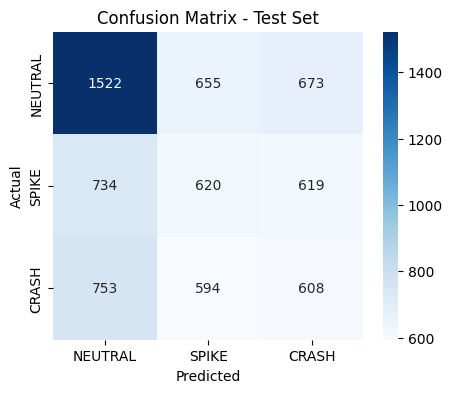

In [16]:
# cell: evaluation
model.load_state_dict(torch.load("models/best_stock_impact_model.pt", map_location=cfg.DEVICE))
model.eval()

def evaluate_model(model, data_loader):
    y_true, y_pred = [], []
    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch["input_ids"].to(cfg.DEVICE)
            attention_mask = batch["attention_mask"].to(cfg.DEVICE)
            numeric_feats = batch["numeric_feats"].to(cfg.DEVICE)
            labels = batch["labels"].to(cfg.DEVICE)

            logits = model(input_ids, attention_mask, numeric_feats)
            preds = torch.argmax(logits, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    return y_true, y_pred

target_names = ["NEUTRAL", "SPIKE", "CRASH"]

if len(test_df) > 0:
    y_true, y_pred = evaluate_model(model, test_loader)
    report = classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=target_names, zero_division=0)
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    logger.info("\n" + report)
    print(report)

    plt.figure(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix - Test Set")
    plt.show()
else:
    logger.warning("Test split contains 0 records. Skipping evaluation.")

## Step 11 - End-to-End Inference on a New Headline

In [17]:
# cell: inference
def predict_headline_impact(headline, news_time=None):
    if news_time is None:
        news_time = pd.Timestamp.now(tz="America/New_York")

    cleaned = clean_headline(headline)
    ticker = resolve_ticker(cleaned, None, None)
    if not ticker:
        return f"Unable to map headline to any monitored company: '{headline}'"

    row = pd.DataFrame({"Headline": [cleaned], "News_Time": [news_time]})
    numeric_feat = build_numeric_features(row)
    numeric_feat_scaled = scaler.transform(numeric_feat)

    encoding = tokenizer(cleaned, return_tensors="pt", truncation=True, padding="max_length", max_length=cfg.MAX_LEN)
    input_ids = encoding["input_ids"].to(cfg.DEVICE)
    attention_mask = encoding["attention_mask"].to(cfg.DEVICE)
    numeric_tensor = torch.tensor(numeric_feat_scaled, dtype=torch.float32).to(cfg.DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(input_ids, attention_mask, numeric_tensor)
        probs = torch.softmax(logits, dim=1).squeeze().cpu().numpy()

    class_map = {0: "NEUTRAL", 1: "SPIKE", 2: "CRASH"}
    pred_class = class_map[int(np.argmax(probs))]

    print("================ Prediction Result ================")
    print(f"Raw Headline:     '{headline}'")
    print(f"Mapped Ticker:    {ticker}")
    print(f"Predicted Impact: {pred_class}")
    print(f"Confidence:       Neutral: {probs[0]:.2f} | Spike: {probs[1]:.2f} | Crash: {probs[2]:.2f}")
    print("=====================================================")

predict_headline_impact("NVIDIA announces breakthrough next-gen AI chip with unprecedented speed")
predict_headline_impact("Tesla faces major supply chain failure and stock plunges sharply")

================ Prediction Result ================
Raw Headline:     'NVIDIA announces breakthrough next-gen AI chip with unprecedented speed'
Mapped Ticker:    NVDA
Predicted Impact: SPIKE
Confidence:       Neutral: 0.05 | Spike: 0.48 | Crash: 0.46
================ Prediction Result ================
Raw Headline:     'Tesla faces major supply chain failure and stock plunges sharply'
Mapped Ticker:    TSLA
Predicted Impact: CRASH
Confidence:       Neutral: 0.04 | Spike: 0.25 | Crash: 0.71


## Step 12 - Export Artifacts

In [18]:
# cell: package everything for download (works locally, in Colab, or in Kaggle)
import shutil

export_dir = "final_project_assets"
zip_filename = "stock_impact_pipeline"

for sub in ["data", "models", "logs"]:
    if os.path.exists(sub):
        shutil.copytree(sub, f"{export_dir}/{sub}", dirs_exist_ok=True)

shutil.make_archive(zip_filename, "zip", export_dir)
print(f"Saved bundle to {zip_filename}.zip")

try:
    from google.colab import files
    files.download(f"{zip_filename}.zip")
except ImportError:
    local_zip_path = os.path.abspath(zip_filename + ".zip")
    print(f"Not running in Google Colab - the zip file is available locally at '{local_zip_path}'.")

Saved bundle to stock_impact_pipeline.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>